In [ ]:
import yfinance as yf
import datetime as dt
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import pearsonr
import numpy as np


In [ ]:
# assets = ['BTC-USD', 'GC=F', 'JPM', 'BAC', 'WFC', 'C', 'GS', 'MS', 'PNC', 'USB','AAPL', 'MSFT', 'GOOGL', 'AMZN', 'NVDA', 'META', 'TSLA', 'INTC', 'CSCO','JNJ', 'PFE', 'UNH', 'MRK', 'LLY', 'ABBV', 'GILD', 'TMO', 'MRNA','AMT', 'PLD', 'CCI', 'SPG', 'PSA', 'EQIX', 'O', 'VNO', 'AVB','SCHW', 'BLK', 'GS', 'MS', 'RJF', 'TROW', 'AMP', 'IBKR']
# assets = ['GILD','MRK']
assets = ['UUP','GC=F','KC=F','ZW=F','ZS=F','SB=F','HG=F','JPM', 'BAC','TSLA','AAPL','KO','USDJPY=X','VNQ','IEF','BTC-USD']


data1 = yf.download(assets, period = 'max')['Close'].ffill().dropna()
print(data1.index[0])
df = data1.reset_index()
df.drop(columns=['Date'], inplace=True)
data = df.pct_change()
# data






[*********************100%***********************]  16 of 16 completed


2014-09-17 00:00:00


0.06123273939416205


<Axes: >

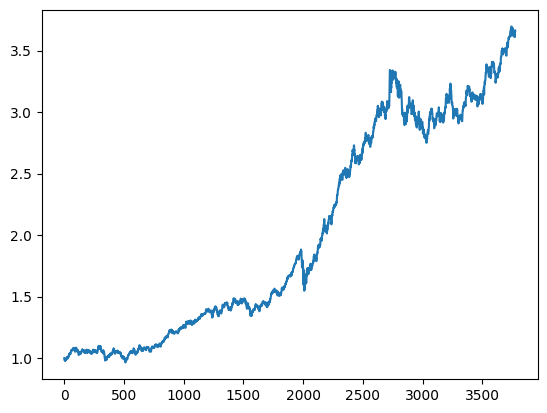

In [ ]:
weight = [1/6,1/36,1/36,1/36,1/36,1/36,1/36,1/30,1/30,1/30,1/30,1/30,1/6,1/12,1/12,1/6]
ret = (data*weight).sum(axis =1 )
sharpe_ret = ret.mean()/ret.std()
print(sharpe_ret)
ret_cum = (ret+1).cumprod()
ret_cum.plot()

In [ ]:
num_assets  = 6
threshold = 0.8
balance_time = 252

In [ ]:
#weight by momentum

def port(start):

  checked_data = data[start - balance_time:start]
  returns = checked_data.dropna()
  corr_matrix = returns.corr()
  mean_correlation = corr_matrix.mean()

  # Filter assets with mean correlation below the threshold
  eligible_assets = mean_correlation[mean_correlation < threshold]

  # Select up to `num_assets` assets with the lowest mean correlations
  selected_assets_raw = eligible_assets.nsmallest(num_assets).index
  port = [item.replace('returns', '').strip() for item in selected_assets_raw]
  end = start + balance_time
  forward_returns = data[port][start:end]
  momentum_checked = (returns[port]+1).cumprod().iloc[-1]
  max_momentum = momentum_checked.max()
  min_momentum = momentum_checked.min()
  momentum_rank = 2*(momentum_checked - min_momentum)/(max_momentum - min_momentum) - 1
  weight = 1-momentum_rank/momentum_rank.sum()

  port_return = ((forward_returns*weight).sum(axis=1) +1).cumprod()[end-1] -1
  print (weight)

  return port,port_return
# #weight by sharpe
# def port(start):

#   checked_data = data[start - balance_time:start]
#   returns = checked_data.dropna()
#   corr_matrix = returns.corr()
#   mean_correlation = corr_matrix.mean()

#   # Filter assets with mean correlation below the threshold
#   eligible_assets = mean_correlation[mean_correlation < threshold]

#   # Select up to `num_assets` assets with the lowest mean correlations
#   selected_assets_raw = eligible_assets.nsmallest(num_assets).index
#   port = [item.replace('returns', '').strip() for item in selected_assets_raw]
#   end = start + balance_time
#   forward_returns = data[port][start:end]
#   sharpe_checked = returns[port].mean()/returns[port].std()
#   max_sharpe = sharpe_checked.max()
#   min_sharpe = sharpe_checked.min()
#   sharpe_rank = 2*(sharpe_checked - min_sharpe)/(max_sharpe - min_sharpe) - 1
#   weight = sharpe_rank/sharpe_rank.sum()
#   port_return = ((forward_returns*weight).sum(axis=1) +1).cumprod()[end-1] -1
#   print (weight)

#   return port,port_return
# #weight by MA return
# def port(start):

#   # checked_data = data[start - 252:start]
#   # returns = checked_data.dropna()
#   df_check = df[start-252:start]
#   long_period = 20
#   ret_check= pd.DataFrame()
#   for column in df_check:
#     symbol = pd.DataFrame()
#     symbol['price'] = df_check[column]
#     symbol['MA_long'] = symbol['price'].rolling(window=long_period).mean()
#     symbol['MA_short'] = symbol['price'].rolling(window=5).mean()
#     symbol['signal'] = np.where(symbol['MA_short'] > symbol['MA_long'], 1, -1)
#     symbol['ret'] = symbol['price'].pct_change()
#     symbol['strategy'] = symbol['signal'].shift(1) * symbol['ret']
#     ret_check = pd.concat([ret_check, symbol['strategy'].rename(column)], axis=1)
#   corr_matrix = ret_check.corr()
#   mean_correlation = corr_matrix.mean()

#   # Filter assets with mean correlation below the threshold
#   eligible_assets = mean_correlation[mean_correlation < threshold]

#   # Select up to `num_assets` assets with the lowest mean correlations
#   selected_assets_raw = eligible_assets.nsmallest(num_assets).index
#   port = [item.replace('returns', '').strip() for item in selected_assets_raw]
#   end = start + balance_time

#   df_port = df[port][start-long_period:end]
#   ret_combined= pd.DataFrame()
#   for column in df_port:
#     symbol = pd.DataFrame()
#     symbol['price'] = df_port[column]
#     symbol['MA_long'] = symbol['price'].rolling(window=long_period).mean()
#     symbol['MA_short'] = symbol['price'].rolling(window=5).mean()
#     symbol['signal'] = np.where(symbol['MA_short'] > symbol['MA_long'], 1, -1)
#     symbol['ret'] = symbol['price'].pct_change()
#     symbol['strategy'] = symbol['signal'].shift(1) * symbol['ret']
#     ret_combined = pd.concat([ret_combined, symbol['strategy']], axis=1) # Using ret_comnbined


#   weight = 1/len(port)
#   port_return = ((ret_combined*weight).sum(axis=1)+1).cumprod()[end-1] - 1

#   return port,port_return

#weight by MVO


In [ ]:
# prompt: weight a portfolio by MVO

# def port(start):
#   checked_data = data[start - balance_time:start]
#   returns = checked_data.dropna()
#   corr_matrix = returns.corr()
#   mean_correlation = corr_matrix.mean()

#   # Filter assets with mean correlation below the threshold
#   eligible_assets = mean_correlation[mean_correlation < threshold]

#   # Select up to `num_assets` assets with the lowest mean correlations
#   selected_assets = eligible_assets.nsmallest(num_assets).index # Changed 'port' to 'selected_assets'
#   mean_returns = returns[selected_assets].mean()
#   cov_matrix = returns[selected_assets].cov()

#   # Define the optimization problem
#   # num_assets = len(returns.columns)
#   # Set the risk aversion parameter (adjust as needed)
#   risk_aversion = 1

#   # Constraints: weights must sum to 1 and be non-negative
#   constraints = ({'type': 'eq', 'fun': lambda x: np.sum(x) - 1})
#   bounds = [(0, 1) for _ in range(num_assets)]  # Non-negative weights

#   # Initial guess for weights (equal weights)
#   initial_weights = np.array([1 / len(selected_assets)] * len(selected_assets)) # Changed 'port' to 'selected_assets'

#   # Optimization function (to minimize negative Sharpe ratio)
#   def negative_sharpe_ratio(weights):
#       portfolio_return = np.sum(mean_returns * weights)
#       portfolio_std_dev = np.sqrt(np.dot(weights.T, np.dot(cov_matrix, weights)))
#       return -(portfolio_return / portfolio_std_dev)

#   # Use minimize function from scipy.optimize
#   from scipy.optimize import minimize
#   optimized_results = minimize(negative_sharpe_ratio, initial_weights, method='SLSQP', bounds=bounds, constraints=constraints)

#   # Optimal weights
#   optimal_weights = optimized_results.x

#   #portfolio creation
#   # port = list(returns.columns) # Removed this line - kept 'selected_assets'
#   end = start + balance_time
#   forward_returns = data[selected_assets][start:end] # Changed 'port' to 'selected_assets'
#   port_return = ((forward_returns*optimal_weights).sum(axis=1) +1).cumprod()[end-1] -1

#   return selected_assets, port_return # Changed 'port' to 'selected_assets'

In [ ]:
port(1000)

Ticker
UUP         0.736107
IEF         0.729374
GC=F        0.728365
USDJPY=X    0.747454
JPM         0.787065
BTC-USD     1.271635
Name: 999, dtype: float64


(['UUP', 'IEF', 'GC=F', 'USDJPY=X', 'JPM', 'BTC-USD'], 5.293423840785861)

In [ ]:
portfolio_returns = []

i = balance_time
while i < data.index[-1]:
  portfolio, portfolio_return = port( i)
  portfolio_returns.append(portfolio_return)
  print (f'At {i} port is {portfolio} \n portfolio_return is {portfolio_return}')
  if i + 2*balance_time <= data.index[-1]:
    i += balance_time
  else:
    break


Ticker
IEF         0.570707
UUP         0.420096
USDJPY=X    0.419398
GC=F        0.745491
KC=F        1.263707
BTC-USD     1.580602
Name: 251, dtype: float64
At 252 port is ['IEF', 'UUP', 'USDJPY=X', 'GC=F', 'KC=F', 'BTC-USD'] 
 portfolio_return is 0.7365596520300401
Ticker
IEF         0.771593
GC=F        0.680795
BTC-USD     1.319205
ZW=F        0.694457
USDJPY=X    0.725616
SB=F        0.808335
Name: 503, dtype: float64
At 504 port is ['IEF', 'GC=F', 'BTC-USD', 'ZW=F', 'USDJPY=X', 'SB=F'] 
 portfolio_return is 1.750269854965294
Ticker
IEF         0.356180
UUP         0.281103
GC=F        0.549972
USDJPY=X    0.017203
SB=F        1.982797
BTC-USD     1.812745
Name: 755, dtype: float64
At 756 port is ['IEF', 'UUP', 'GC=F', 'USDJPY=X', 'SB=F', 'BTC-USD'] 
 portfolio_return is 2.5019416281670783
Ticker
UUP         0.735225
GC=F        0.733526
IEF         0.733078
USDJPY=X    0.747699
BTC-USD     1.266922
JPM         0.783550
Name: 1007, dtype: float64
At 1008 port is ['UUP', 'GC=F', '

0.5464026305558605


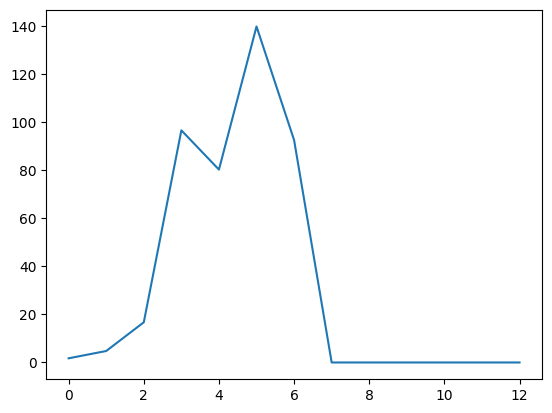

In [ ]:
portfolio_returns = pd.Series(portfolio_returns)
port_cum = (1+portfolio_returns).cumprod()
port_sharpe = portfolio_returns.mean()/portfolio_returns.std()
print(port_sharpe)
plt.plot(port_cum)